# 01 – Statistics Foundations: Which number is "the typical order"?

**Business question:** A shop reports its *average order value* to management.
Is the average a fair picture of a typical customer — or can a single large order distort it?

**Data:** `ecommerce_orders.csv` — 12 simulated orders (order_id, customer_id, order_value in EUR).
The dataset is deliberately small so every number can be checked by hand.

**Steps:** 1. load & validate · 2. describe · 3. find outliers · 4. measure their effect · 5. recommendation

> The calculations live in `stats_foundations.py` and are covered by `tests/test_stats_foundations.py`,
> so the notebook and the tests use the same logic.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import stats_foundations as sf

orders = sf.load_orders()   # raises if columns are missing, ids repeat or values are not positive
orders

,order_id,customer_id,order_value
0,1,101,20
1,2,102,22
2,3,103,19
3,4,104,23
4,5,105,21
5,6,106,20
6,7,107,24
7,8,108,500
8,9,109,18
9,10,110,25


## 2. Describe: mean vs. median

In [2]:
stats = sf.describe(orders["order_value"])
pd.Series(stats).round(2).to_frame("value")

,value
n,12.00
mean,61.25
median,21.50
std,138.19
q1,20.00
q3,23.25
iqr,3.25
min,18.00
max,500.00


The **mean is 61.25 EUR**, the **median 21.50 EUR** — almost three times apart.
Only **1 of 12 orders** lies above the mean. A KPI that describes almost no one is a poor "typical" value.

## 3. Find outliers (Tukey's 1.5 × IQR rule)

In [3]:
mask = sf.iqr_outliers(orders["order_value"])
q1, q3, iqr = stats["q1"], stats["q3"], stats["iqr"]
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Upper fence = Q3 + 1.5 * IQR = {q3 + 1.5 * iqr:.2f} EUR")
orders[mask]

Q1 = 20.00, Q3 = 23.25, IQR = 3.25
Upper fence = Q3 + 1.5 * IQR = 28.12 EUR


,order_id,customer_id,order_value
7,8,108,500


## 4. How much does the outlier move each statistic?

In [4]:
effect = sf.outlier_effect(orders["order_value"])
summary = pd.DataFrame({
    "with outlier":    [effect["mean_with"], effect["median_with"]],
    "without outlier": [effect["mean_without"], effect["median_without"]],
    "shift %":         [effect["mean_shift_pct"], effect["median_shift_pct"]],
}, index=["mean", "median"]).round(2)
print(f"Outlier share of total revenue: {effect['outlier_revenue_share']:.1%}")
print(f"10 % trimmed mean: {sf.trimmed_mean(orders['order_value']):.2f} EUR")
summary

Outlier share of total revenue: 68.0%
10 % trimmed mean: 21.70 EUR


,with outlier,without outlier,shift %
mean,61.25,21.36,186.70
median,21.50,21.00,2.38


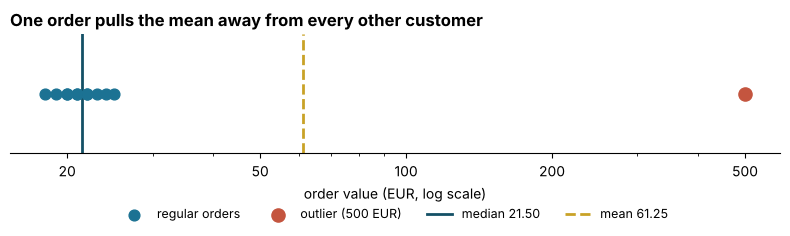

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.8))
v = orders["order_value"]
ax.scatter(v[~mask], [0] * (~mask).sum(), color="#1C7293", s=60, label="regular orders", zorder=3)
ax.scatter(v[mask], [0] * mask.sum(), color="#C4553F", s=90, label="outlier (500 EUR)", zorder=3)
ax.axvline(stats["median"], color="#145066", lw=2, label=f"median {stats['median']:.2f}")
ax.axvline(stats["mean"], color="#C9A227", lw=2, ls="--", label=f"mean {stats['mean']:.2f}")
ax.set_xscale("log")
from matplotlib.ticker import NullFormatter
ax.set_xticks([20, 50, 100, 200, 500]); ax.set_xticklabels(["20", "50", "100", "200", "500"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([]); ax.set_xlabel("order value (EUR, log scale)")
ax.set_title("One order pulls the mean away from every other customer", loc="left", fontsize=12, fontweight="bold")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("figures/mean_vs_median.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Recommendation

| Finding | Number |
|---|---|
| Mean order value | 61.25 EUR |
| Median order value | 21.50 EUR |
| Orders above the mean | 1 of 12 |
| Revenue share of the single 500 EUR order | 68.0 % |
| Mean shift caused by the outlier | +186.7 % |
| Median shift caused by the outlier | +2.4 % |

1. **Report the median as the typical order value**, and the mean only next to it — the gap itself is a signal.
2. **Report large orders separately.** One order carries two thirds of revenue; losing that customer matters more than any trend in the other eleven.
3. **Check the distribution before choosing a KPI.** Here the IQR rule flags the outlier with a clear fence (28.13 EUR); a data error and a genuine key account look the same in the numbers, so the next step is to ask the business which one it is.

**Limits:** 12 simulated orders show the mechanism, not a real shop. On real data the same steps apply, but the outlier rule should be checked against domain knowledge (B2B orders, returns, test orders).